# Lecture 1

Settings that make the plots look pretty on my Mac:

In [1]:
%pylab inline
%config InlineBackend.figure_format = 'retina'

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


You will need 

* [corner](https://github.com/dfm/corner.py).  Makes "corner" plots of distributions from samples.
* [numpyro](https://num.pyro.ai) (built on [jax](https://jax.readthedocs.io)).  `pip install numpyro` has always worked well for me.  (Even easier: install [uv](https://docs.astral.sh/uv/) and run `uv run jupyter lab` from the root of the repository; this sets up everything you need for all the lectures.)
* [arviz](https://python.arviz.org).  For plotting the output of the sampler.
* [seaborn](https://seaborn.pydata.org).  `pip install seaborn`.  Seaborn is a plotting library.

In [2]:
import arviz as az
import corner
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import seaborn as sns

numpyro.set_host_device_count(4) # Run four chains in parallel
numpyro.enable_x64() # Double precision

These are my favourite plotting styles:

In [3]:
sns.set_context('talk') #sns.set_context('notebook') is probably better on your monitor
sns.set_palette('colorblind')
sns.set_style('ticks')

## Preliminaries (Notes)

* $p(d, \theta) = p\left( d \mid \theta \right) p\left( \theta \right) = p\left( \theta \mid d \right) p\left( d \right)$ is the fundamental quantity.  A "just so" story about how you obtained your data.
* Dimensions / forms.
* Sampling from versus writing down; normalisation.
* Almost always computing.
* One way to think about it is that $p$ describes *knowledge*.  For example:
  * If I knew $\theta$, what would I predict about $d$.
  * If I knew $d$, what would I predict about $\theta$.
* Marginalisation.

## Let's Get Started Fitting

We are going to focus today on [Hogg, et al. (2010)](https://arxiv.org/abs/1008.4686).  In this paper, the "just so" story will be evolving, but it always involves measuring data `x` and `y` which are (often) related by a linear relationship:
$$
y = m x + b
$$
For some reason (maybe we are cosmologists?) we are interested in the parameters $m$ and $b$.  Please read Hogg, et al. (2010)'s cautionary note about this!

* Warning about interpretation of b (we will explore this)!

I used [tabula](http://tabula.technology) to scrape the data table from Hogg's PDF.  When *you* post things on the arXiv, *you* should always include a link to machine readable tables to accompany the document.  You can post your data on [GitHub](https://github.com), or if you want more archive-quality repositories that are citable (e.g. generate a DOI), consider something like [Zenodo](https://zenodo.org).  Hogg & company, normally so good in this respect, dropped the ball for this paper.

In [4]:
table1 = genfromtxt('HoggTable1.tsv', names=True)

<ErrorbarContainer object of 3 artists>

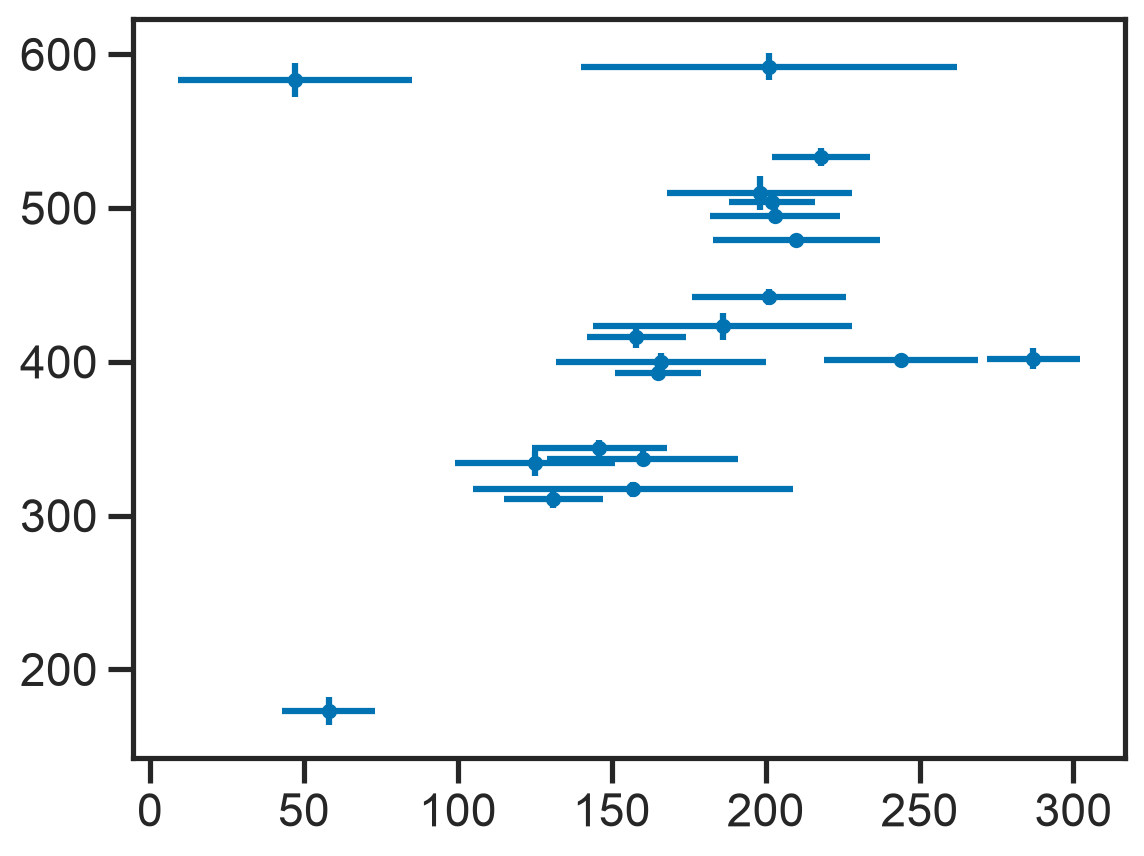

In [5]:
errorbar(table1['x'], table1['y'], xerr=table1['sigma_x'], yerr=table1['sigma_y'], fmt='.')

### Exercise 1

(I know that this can be computed analytically---and Hogg, et al. (2010) tell you how---but we're going to be computing anyway, so let's do it that way first.)

To do some fits, we will be using [NumPyro](https://num.pyro.ai).  NumPyro is a Python library for describing joint distributions of data and parameters: we write the description as an ordinary Python function.  Once the description is written down, NumPyro draws samples from the conditional distribution $p\left( \theta \mid d \right)$ using the same algorithm as [Stan](http://mc-stan.org) (NUTS); [JAX](https://jax.readthedocs.io) differentiates and compiles our function to fast machine code behind the scenes, so we can drive everything from Python.  Whew.

For exercise 1, we assume that 
$$
y_\mathrm{true} = m x_\mathrm{true} + b
$$
and 
$$
y_\mathrm{obs} = y_\mathrm{true} + \sigma_y
$$

* Write NumPyro model.

In [6]:
def model(npts, xs, ys, sigma_ys):
    m = numpyro.sample('m', dist.ImproperUniform(dist.constraints.real, (), ())) # Flat prior
    b = numpyro.sample('b', dist.ImproperUniform(dist.constraints.real, (), ()))

    numpyro.sample('ys', dist.Normal(m*xs + b, sigma_ys), obs=ys)

Exercise 1 asks us to fit all the data from the 5th to the 20th point, and ignore the uncertainty in $y$.

In [7]:
ex1N0 = 4

In [8]:
ex1_data = {'npts': table1['x'][ex1N0:].shape[0],
            'xs': table1['x'][ex1N0:],
            'ys': table1['y'][ex1N0:],
            'sigma_ys': table1['sigma_y'][ex1N0:]}

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
         b      4.20      7.53      4.09     -7.60     17.31    567.84      1.00
         m      2.33      0.04      2.33      2.26      2.40    572.45      1.00

Number of divergences: 0


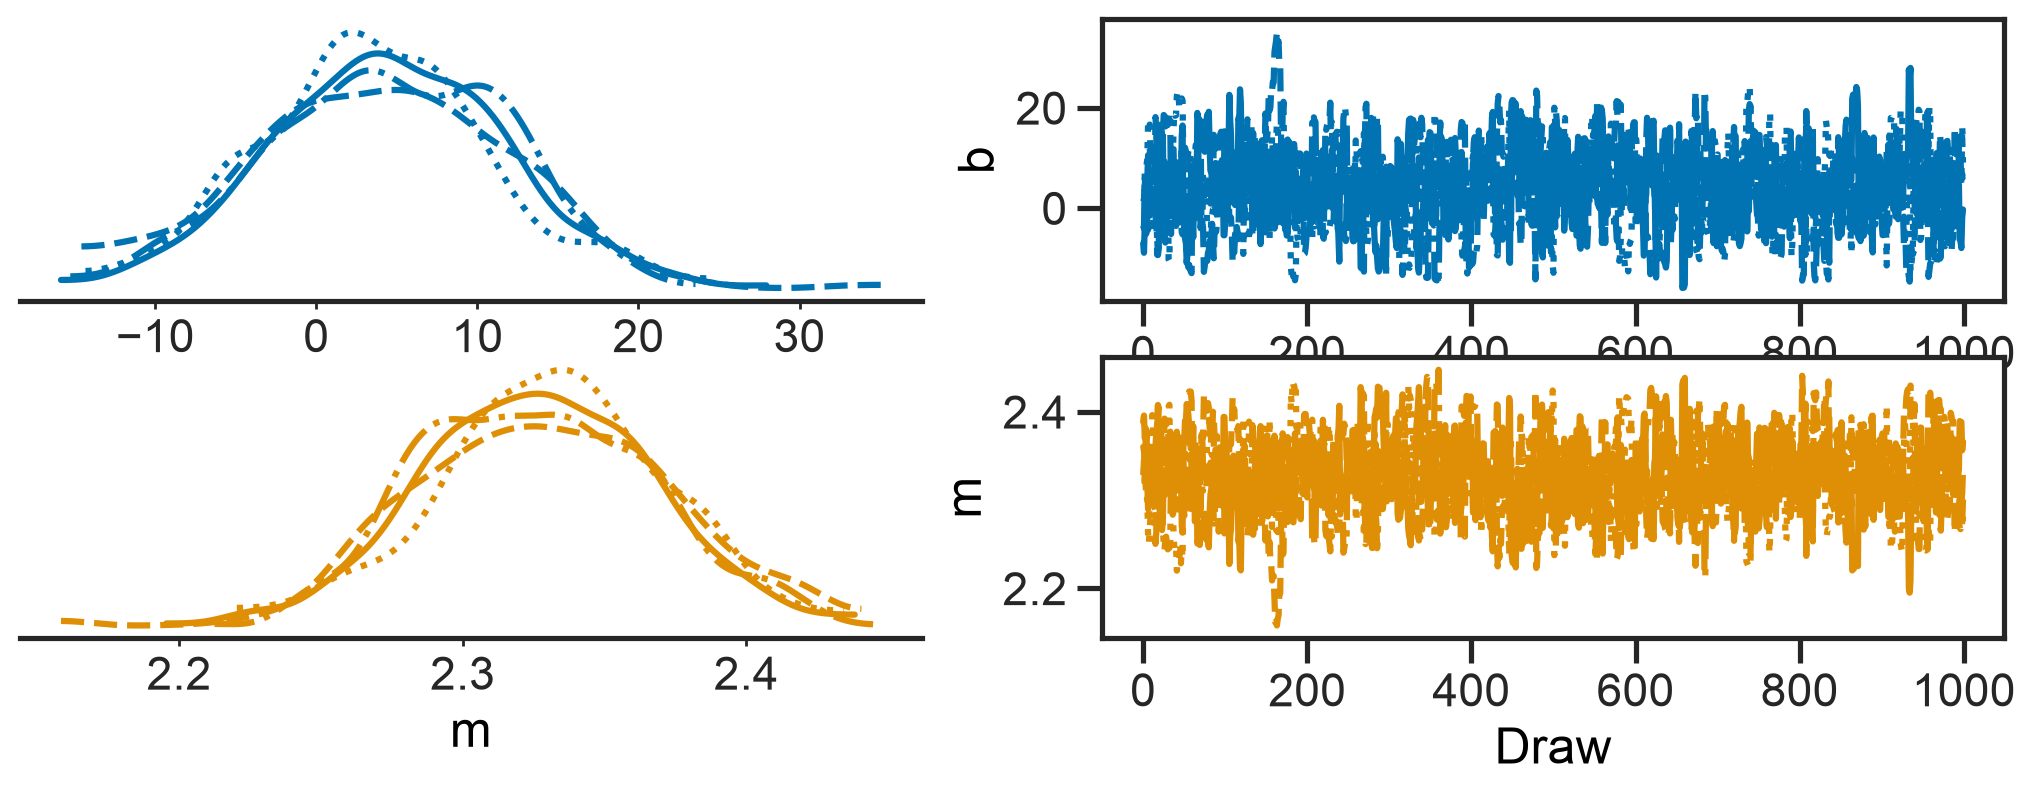

In [9]:
ex1_fit = MCMC(NUTS(model), num_warmup=1000, num_samples=1000, num_chains=4)
ex1_fit.run(jax.random.PRNGKey(0), **ex1_data)
az.plot_trace_dist(az.from_numpyro(ex1_fit))
ex1_fit.print_summary()

In [10]:
ex1_samples = ex1_fit.get_samples()

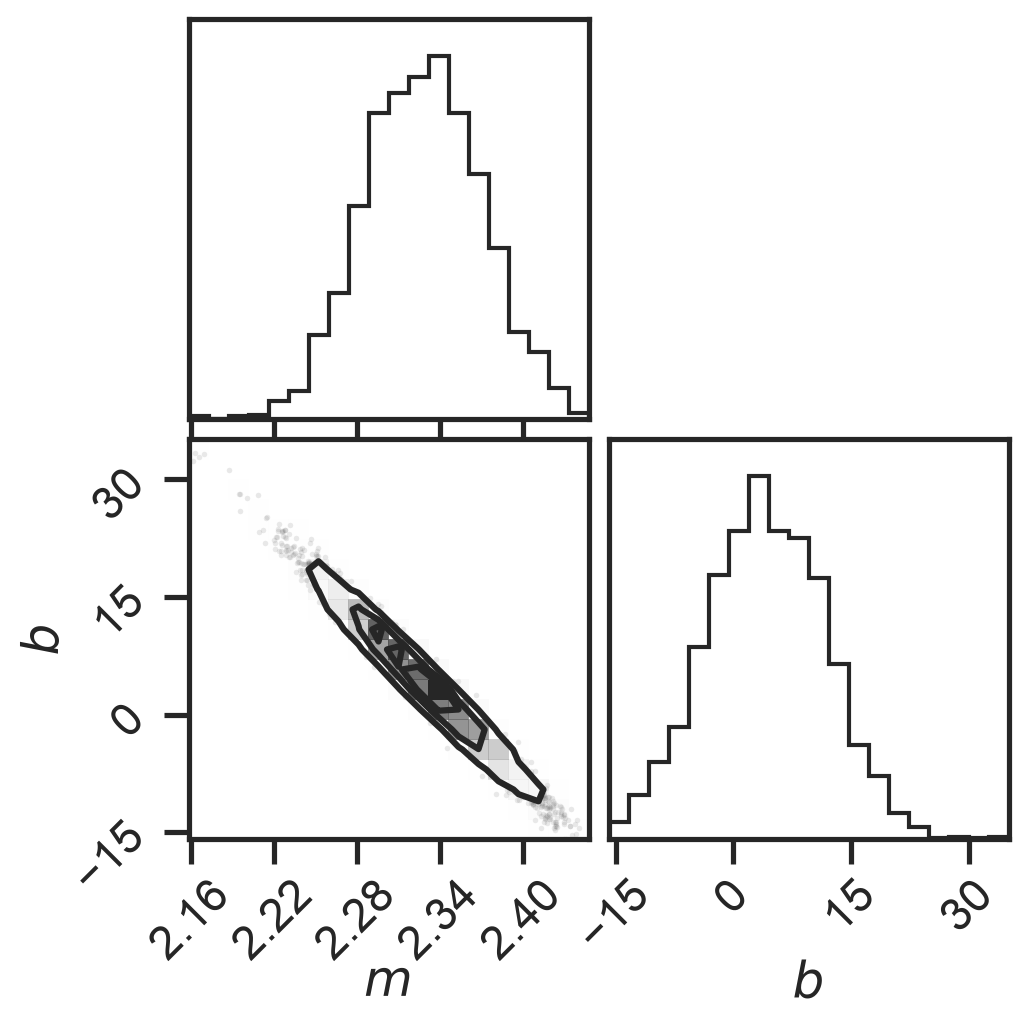

In [11]:
corner.corner(column_stack((ex1_samples['m'], ex1_samples['b'])), labels=[r'$m$', r'$b$']);

We *always* want to plot the output of our models in data space, to check whether the fit is good.  Let's define a function that does this:

In [12]:
def plot_errorbands(xs, ms, bs, *args, **kwargs):
    ys = []
    for m,b in zip(ms, bs):
        ys.append(m*xs + b)
    ys = array(ys)
    
    line, = plot(xs, median(ys, axis=0), *args, **kwargs)
    fill_between(xs, percentile(ys, 84, axis=0), percentile(ys, 16, axis=0), alpha=0.25, color=line.get_color())
    fill_between(xs, percentile(ys, 97.5, axis=0), percentile(ys, 2.5, axis=0), alpha=0.25, color=line.get_color())

A somewhat subtle point: our model has *implications* for $y_\mathrm{true}$.  $y_\mathrm{true} = m x + b$.  Thus we have a posterior on $y_\mathrm{true}$:

In [13]:
def plot_ytrues_no_scatter(xs, ms, bs, *args, **kwargs):
    ytrues = []
    for m,b in zip(ms, bs):
        ytrues.append(m*xs + b)
    ytrues = array(ytrues)
    
    errorbar(xs, mean(ytrues, axis=0), yerr=std(ytrues, axis=0), fmt='.', *args, **kwargs)

You can see that our uncertainty is very small.  In fact, they are so small, that our model is clearly inconsistent with the measurements---the green dots + errorbars are the *model* predictions, and they are *wildly* inconsistent with the data in black.  Something must be done.

<ErrorbarContainer object of 3 artists>

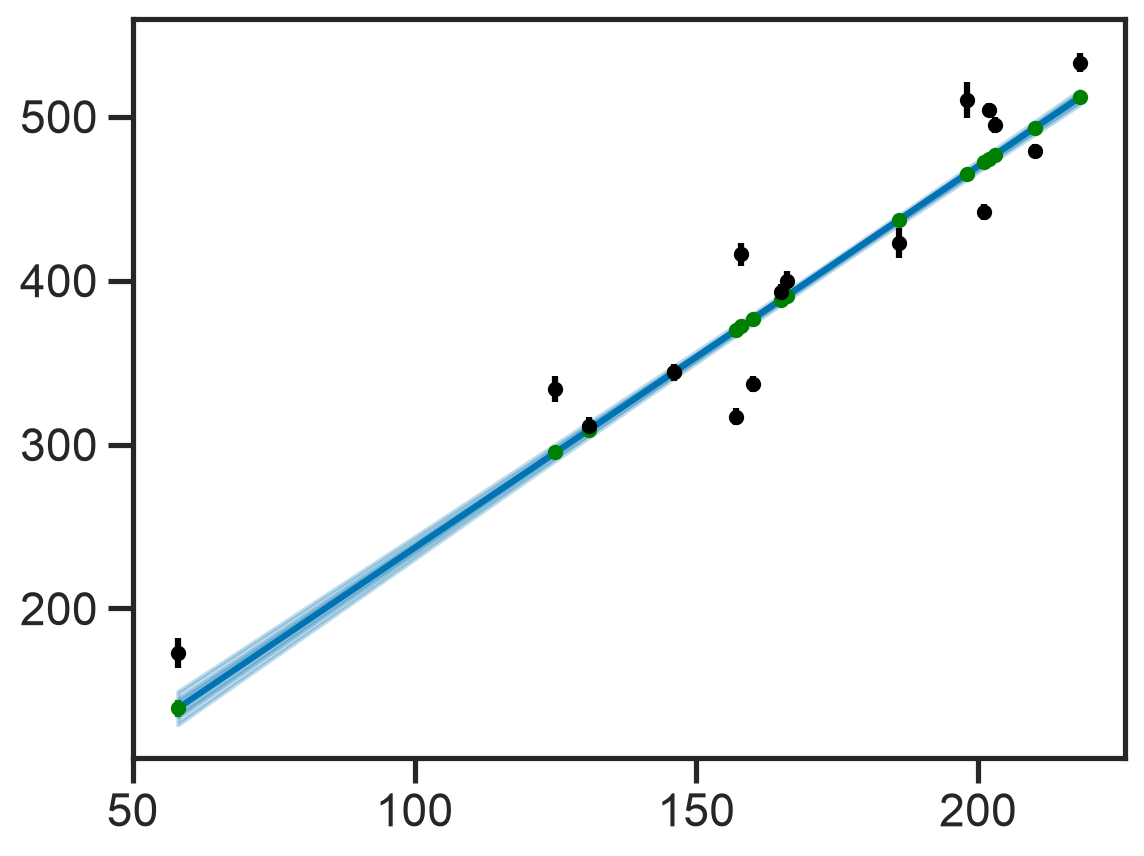

In [14]:
plot_errorbands(linspace(np.min(table1['x'][ex1N0:]), np.max(table1['x'][ex1N0:]), 1000), ex1_samples['m'], ex1_samples['b'])
plot_ytrues_no_scatter(table1['x'][ex1N0:], ex1_samples['m'], ex1_samples['b'], color='g')
errorbar(table1['x'][ex1N0:], table1['y'][ex1N0:], yerr=table1['sigma_y'][ex1N0:], fmt='.', color='k')

Places to go from here:
* Exercise 2: Fit the crappy data.
* Improve the model (it's obviously bad)?
* Better priors?
* Deal with outliers.

Ilya suggested that we try to inflate the observed uncertainties by some constant factor until the fit is good (and I made a lot of fun at his expense because this model is saying you don't trust the observational errorbars---thanks for being a good sport, Ilya).

I have limited the scaling factor between 0.1 and 10.0.

In [15]:
def model_ilya(npts, xs, ys, sigma_ys):
    m = numpyro.sample('m', dist.ImproperUniform(dist.constraints.real, (), ()))
    b = numpyro.sample('b', dist.ImproperUniform(dist.constraints.real, (), ()))
    ilyas_idiot_factor = numpyro.sample('ilyas_idiot_factor', dist.ImproperUniform(dist.constraints.interval(0.1, 10.0), (), ()))
    numpyro.factor('ilyas_idiot_factor_prior', dist.LogNormal(log(1.0), 1.0).log_prob(ilyas_idiot_factor))

    numpyro.sample('ys', dist.Normal(m*xs + b, sigma_ys*ilyas_idiot_factor), obs=ys)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]


                          mean       std    median      5.0%     95.0%     n_eff     r_hat
                   b      4.73     40.40      3.53    -61.45     68.52   1184.68      1.00
  ilyas_idiot_factor      5.31      0.97      5.19      3.72      6.70    713.91      1.01
                   m      2.33      0.22      2.33      1.98      2.71   1173.91      1.00

Number of divergences: 0


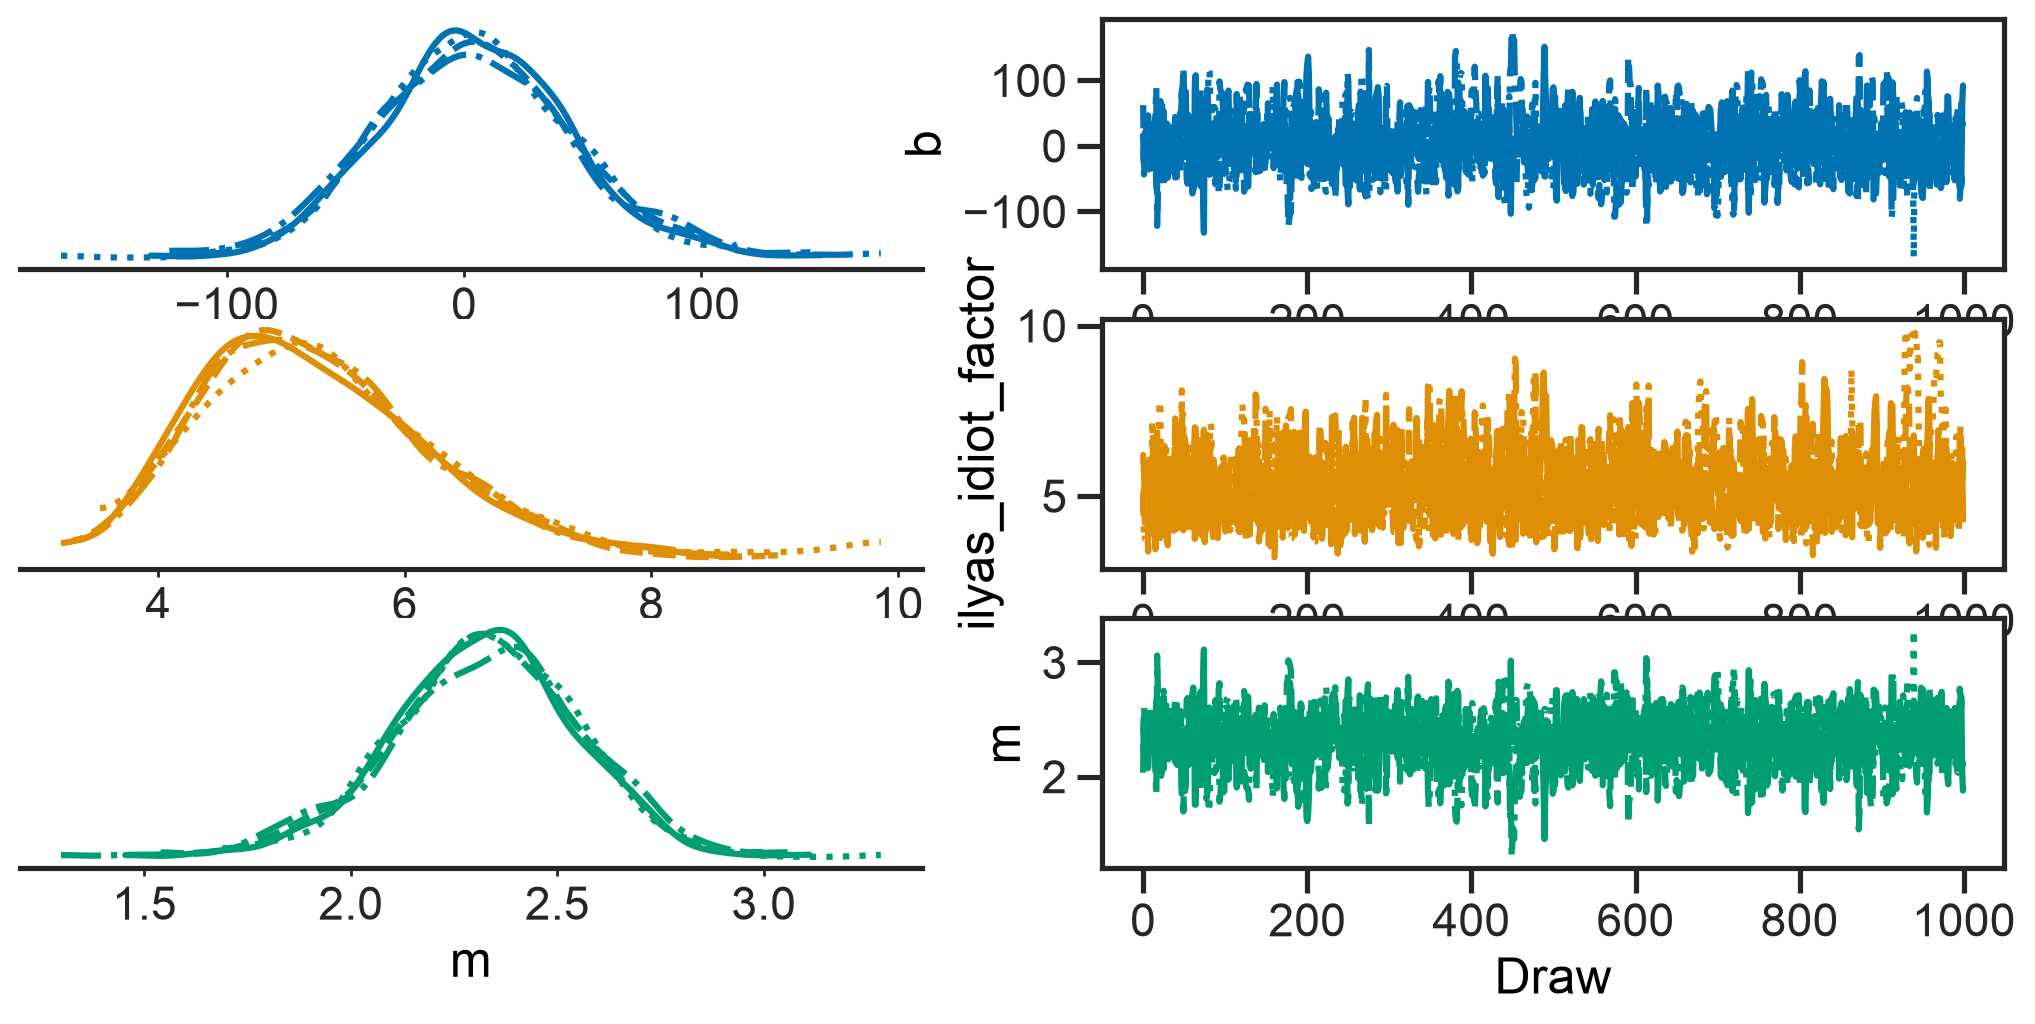

In [16]:
fit_ilya = MCMC(NUTS(model_ilya), num_warmup=1000, num_samples=1000, num_chains=4)
fit_ilya.run(jax.random.PRNGKey(0), **ex1_data)
az.plot_trace_dist(az.from_numpyro(fit_ilya))
fit_ilya.print_summary()

In [17]:
samples_ilya = fit_ilya.get_samples()

In particular, Ilya's suggestion would imply that the observers have under-stated their errorbars by a factor of ~5:

/var/folders/70/vvk0t38122l6ddxl8hbymr480000gp/T/ipykernel_87118/2371772926.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(samples_ilya['ilyas_idiot_factor'])


Text(0, 0.5, '$p\\left( \\mathrm{factor} \\right)$')

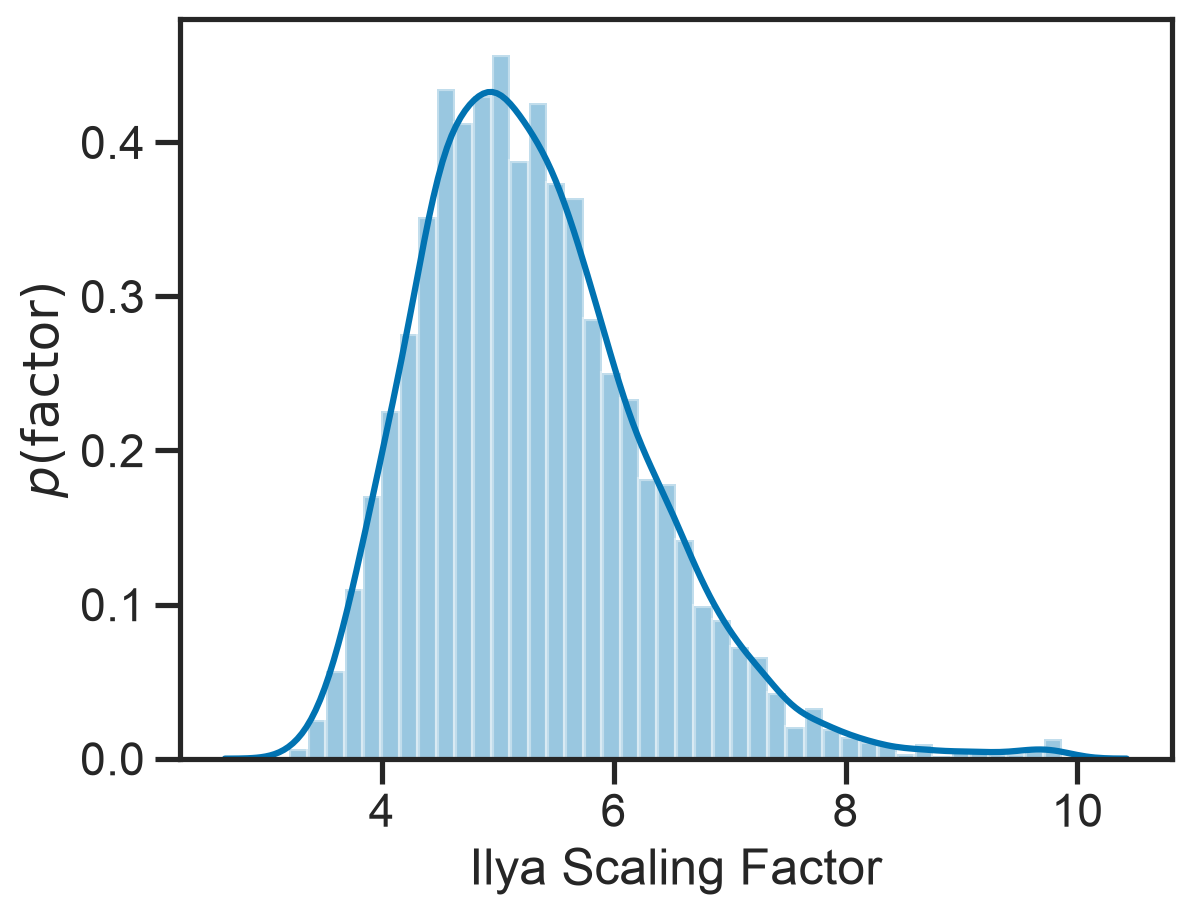

In [18]:
sns.distplot(samples_ilya['ilyas_idiot_factor'])
xlabel('Ilya Scaling Factor')
ylabel(r'$p\left( \mathrm{factor} \right)$')

<ErrorbarContainer object of 3 artists>

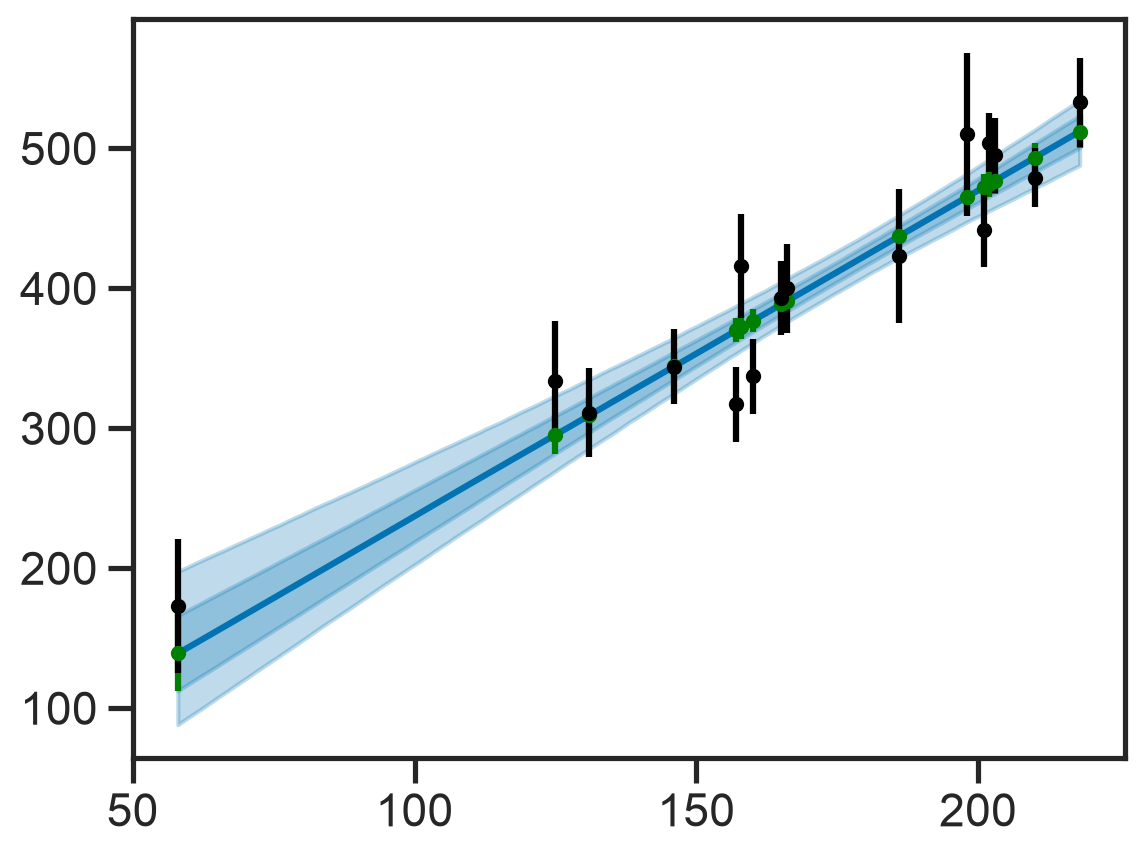

In [19]:
plot_errorbands(linspace(np.min(table1['x'][ex1N0:]), np.max(table1['x'][ex1N0:]), 1000), samples_ilya['m'], samples_ilya['b'])
plot_ytrues_no_scatter(table1['x'][ex1N0:], samples_ilya['m'], samples_ilya['b'], color='g')
errorbar(table1['x'][ex1N0:], table1['y'][ex1N0:], yerr=mean(samples_ilya['ilyas_idiot_factor'], axis=0)*table1['sigma_y'][ex1N0:], fmt='.', color='k')

An alternative model is that the observers got it right, but there is some "intrinsic" scatter in the relation.  We talked about how this could come about in lecture.  Our just-so story is now:
$$
y_\mathrm{true} \sim N\left( m x_\mathrm{true} + b, \sigma \right)
$$
with 
$$
y_\mathrm{obs} \sim N\left( y_\mathrm{true}, \sigma_y \right)
$$

In [20]:
def model_scatter(npts, xs, ys, sigma_ys):
    m = numpyro.sample('m', dist.ImproperUniform(dist.constraints.real, (), ()))
    b = numpyro.sample('b', dist.ImproperUniform(dist.constraints.real, (), ()))
    sigma = numpyro.sample('sigma', dist.ImproperUniform(dist.constraints.positive, (), ()))

    y_true = numpyro.sample('y_true', dist.Normal(m*xs + b, sigma))
    numpyro.sample('ys', dist.Normal(y_true, sigma_ys), obs=ys)

In [21]:
fit_scatter = MCMC(NUTS(model_scatter), num_warmup=1000, num_samples=1000, num_chains=4)
fit_scatter.run(jax.random.PRNGKey(0), **ex1_data)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
         b     27.62     38.13     27.77    -33.82     90.77   3013.01      1.00
         m      2.22      0.22      2.22      1.89      2.60   3017.95      1.00
     sigma     32.95      7.33     31.79     22.59     44.93   3928.88      1.00
 y_true[0]    494.55      4.91    494.53    487.05    503.10   8460.44      1.00
 y_true[1]    171.57      8.88    171.41    157.67    186.26   7471.53      1.00
 y_true[2]    479.19      4.07    479.29    472.19    485.41   7617.76      1.00
 y_true[3]    503.57      4.01    503.55    497.22    510.21   7188.75      1.00
 y_true[4]    505.22     10.47    505.11    488.66    522.62   7831.14      1.00
 y_true[5]    414.17      6.81    414.10    402.81    424.89   7345.41      1.00
 y_true[6]    393.00      4.98    393.07    385.07    401.34   9182.07      1.00
 y_true[7]    442.75      5.03    442.81    434.37    450.84   8148.75      1.00
 y_true[8]    318.49      5

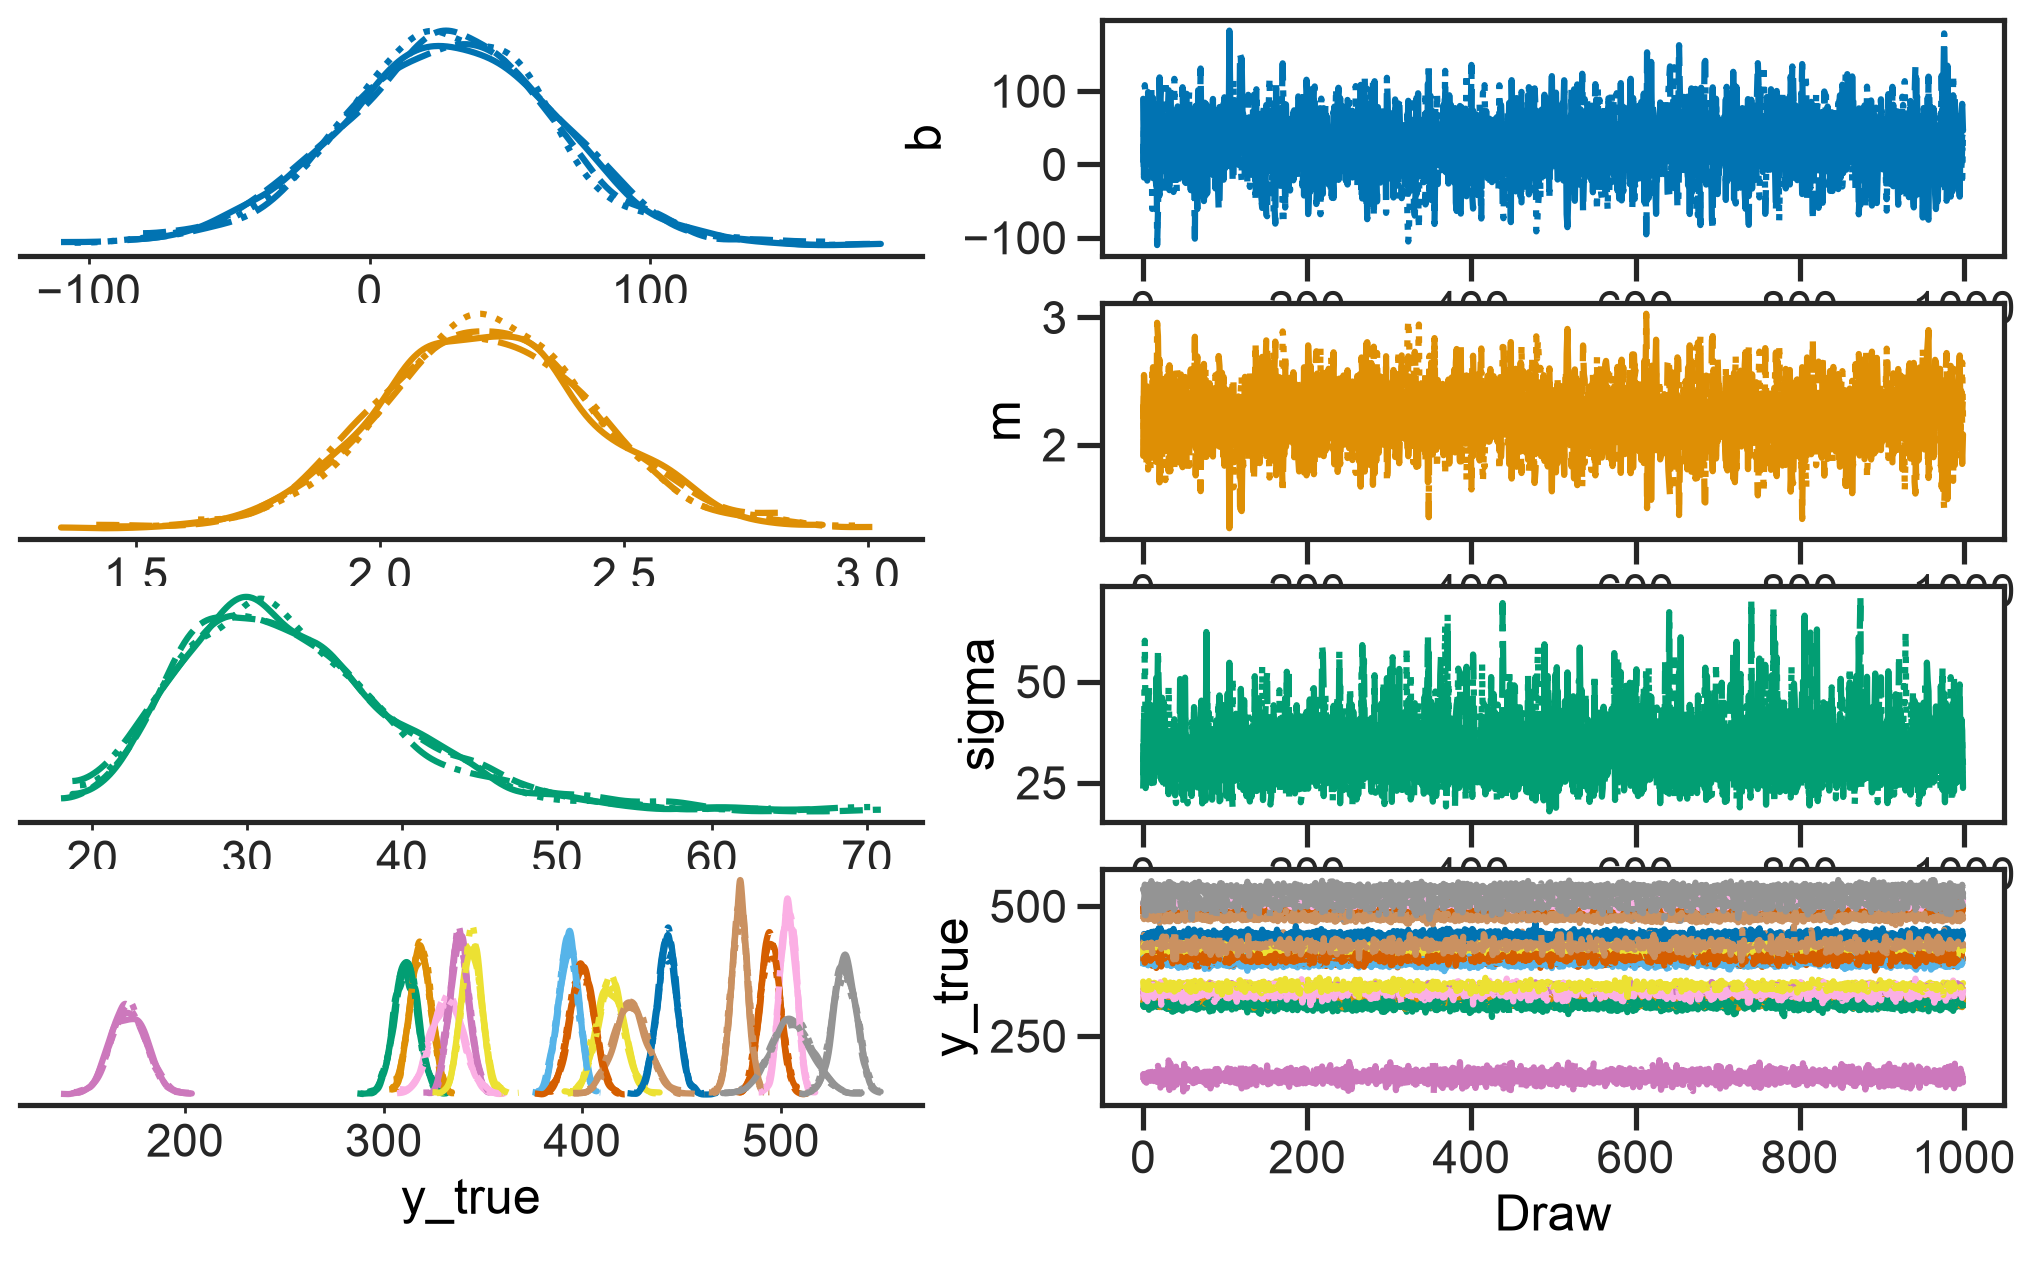

In [22]:
az.plot_trace_dist(az.from_numpyro(fit_scatter))
fit_scatter.print_summary()

In [23]:
samples_scatter = fit_scatter.get_samples()

<ErrorbarContainer object of 3 artists>

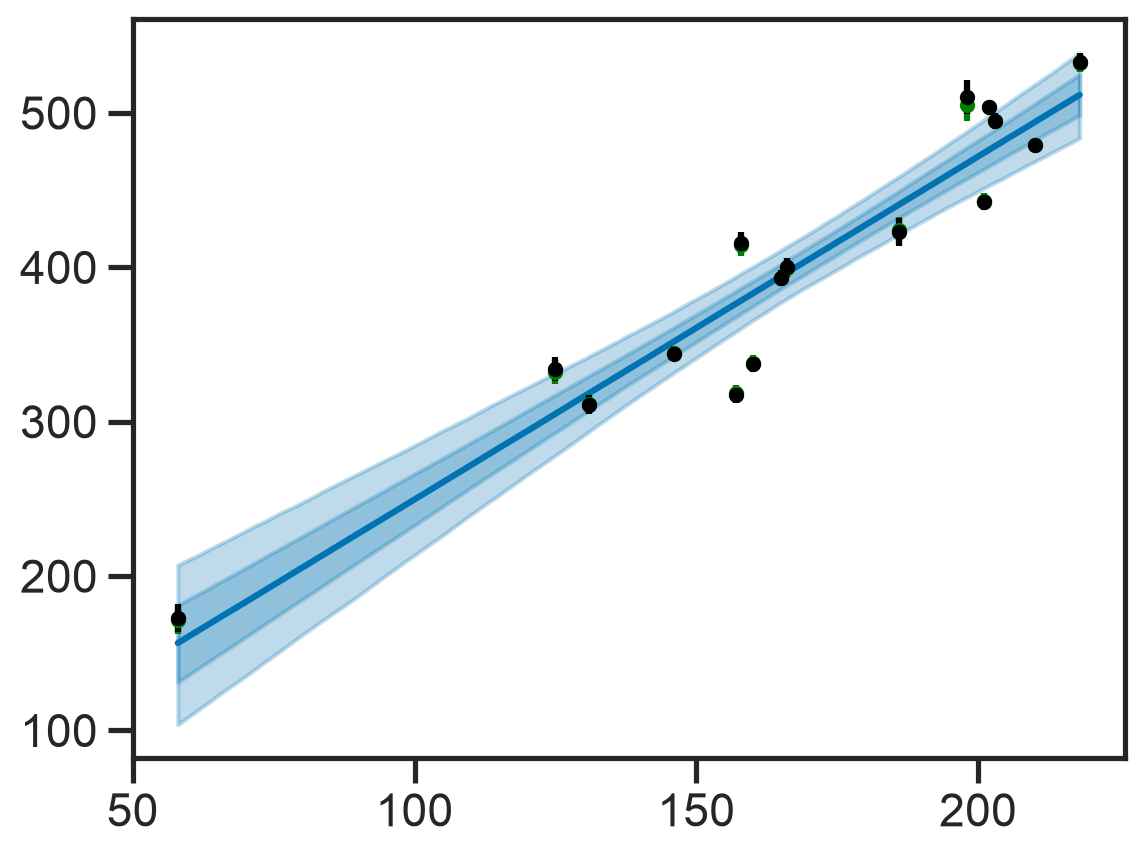

In [24]:
plot_errorbands(linspace(np.min(table1['x'][ex1N0:]), np.max(table1['x'][ex1N0:]), 1000), samples_scatter['m'], samples_scatter['b'])
errorbar(table1['x'][ex1N0:], mean(samples_scatter['y_true'], axis=0), yerr=std(samples_scatter['y_true'], axis=0), fmt='.', color='g')
errorbar(table1['x'][ex1N0:], table1['y'][ex1N0:], yerr=table1['sigma_y'][ex1N0:], fmt='.', color='k')

Note that in the last *three* models, I have sneakily put in posteriors over $y_\mathrm{true}$.  These models are *hierarchical* or *multilevel* or *partially pooled* (different communities have different names for this).  The posterior over $y_\mathrm{true}$ is a *weighted* combination of the observational uncertainty and the modelling uncertainty; by imposing a model, we allow observations of multiple data points to inform each other and reduce the uncertainty.  For example, here is the posterior on $y_\mathrm{true}$ for the worst-measured data point compared to the observational uncertainty.  Because the point lies above the fitted line, the posterior trends lower than the observation, but the error is significantly reduced.

/var/folders/70/vvk0t38122l6ddxl8hbymr480000gp/T/ipykernel_87118/722352753.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(samples_scatter['y_true'][:,ind])


Text(0, 0.5, '$p\\left( y_\\mathrm{true} \\right)$')

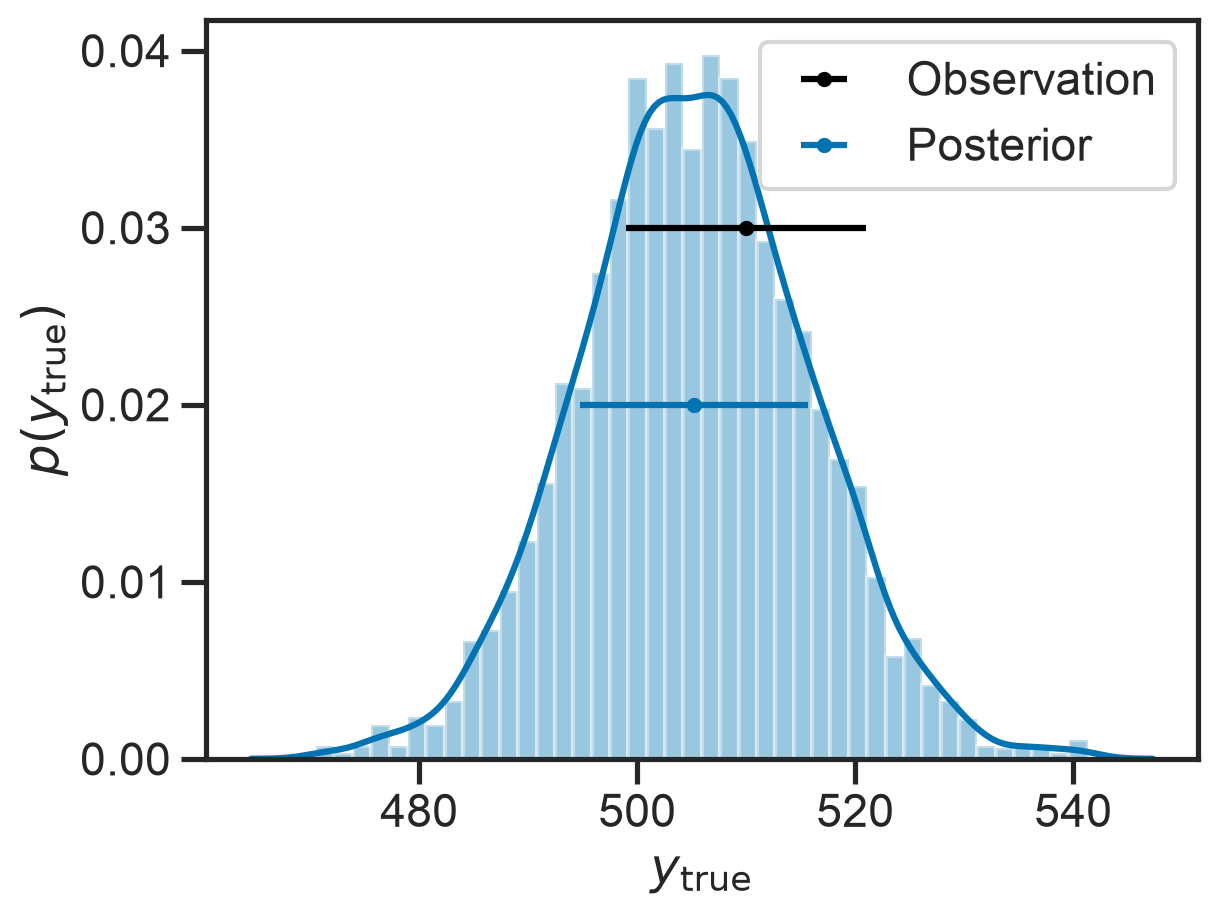

In [25]:
ind = argmax(table1['sigma_y'][ex1N0:])
sns.distplot(samples_scatter['y_true'][:,ind])
errorbar(table1['y'][ex1N0:][ind], 0.030, xerr=table1['sigma_y'][ex1N0:][ind], fmt='.', color='k', label='Observation')
errorbar(mean(samples_scatter['y_true'][:,ind]), 0.020, xerr=std(samples_scatter['y_true'][:,ind]), fmt='.', color=sns.color_palette()[0], label='Posterior')
legend(loc='best')
xlabel(r'$y_\mathrm{true}$')
ylabel(r'$p\left( y_\mathrm{true} \right)$')

Now let's try a fit including the "bad" data at face value:

In [26]:
data_bad = {'npts': table1['x'].shape[0],
            'xs': table1['x'],
            'ys': table1['y'],
            'sigma_ys': table1['sigma_y']}

In [27]:
fit_bad = MCMC(NUTS(model_scatter), num_warmup=1000, num_samples=1000, num_chains=4)
fit_bad.run(jax.random.PRNGKey(0), **data_bad)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
         b    310.84     78.47    311.06    181.67    440.14   2120.32      1.00
         m      0.63      0.44      0.63     -0.09      1.35   2137.85      1.00
     sigma    106.02     19.66    103.24     75.61    135.97   3460.03      1.00
 y_true[0]    590.63      9.04    590.74    576.53    605.83   5028.72      1.00
 y_true[1]    401.02      4.00    401.07    395.03    408.06   5247.98      1.00
 y_true[2]    580.03     11.33    580.02    562.47    599.08   5345.52      1.00
 y_true[3]    402.40      7.06    402.32    391.26    414.07   5722.28      1.00
 y_true[4]    494.82      5.03    494.78    486.82    503.27   5074.45      1.00
 y_true[5]    174.42      9.09    174.31    158.69    188.33   5688.83      1.00
 y_true[6]    478.93      3.99    478.92    472.14    485.19   4433.87      1.00
 y_true[7]    503.99      4.09    503.93    497.10    510.33   4764.83      1.00
 y_true[8]    509.11     11

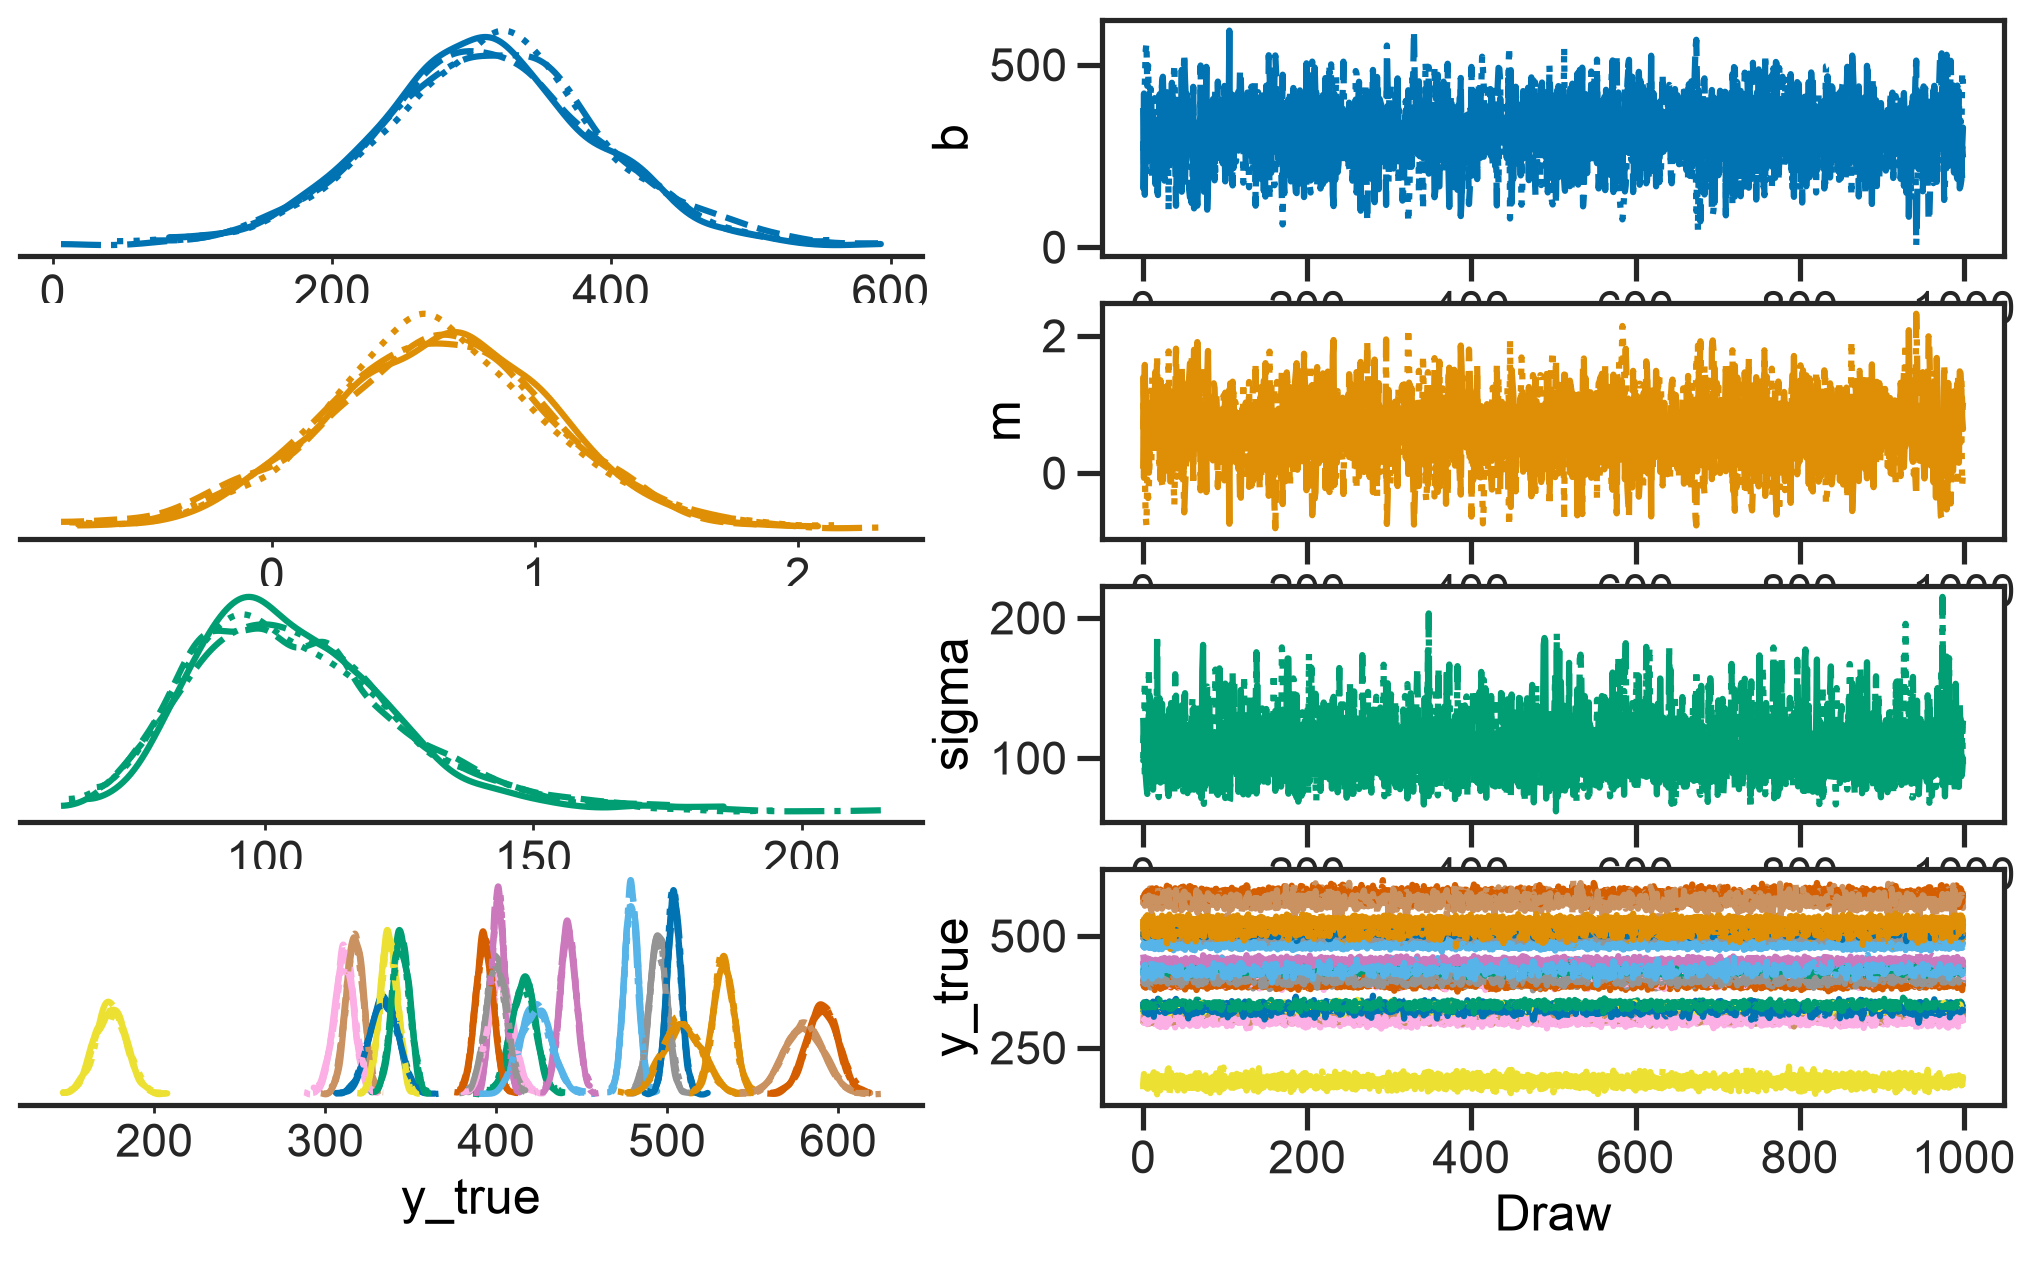

In [28]:
az.plot_trace_dist(az.from_numpyro(fit_bad))
fit_bad.print_summary()

In [29]:
samples_bad = fit_bad.get_samples()

Ugh---that fit is eye-wateringly bad!  The outliers are pulling the slope way down!  How can we reject them?

<ErrorbarContainer object of 3 artists>

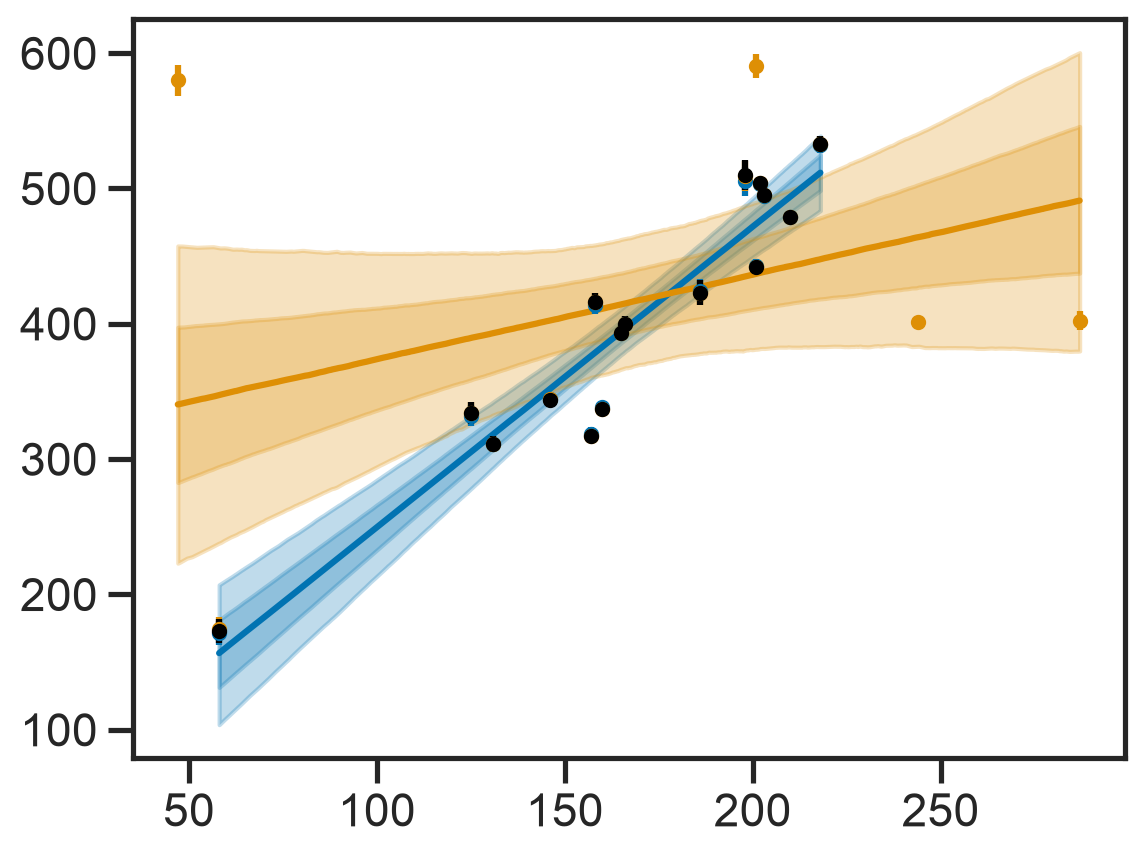

In [30]:
plot_errorbands(linspace(np.min(table1['x'][ex1N0:]), np.max(table1['x'][ex1N0:]), 1000), samples_scatter['m'], samples_scatter['b'])
plot_errorbands(linspace(np.min(table1['x']), np.max(table1['x']), 1000), samples_bad['m'], samples_bad['b'])
errorbar(table1['x'][ex1N0:], mean(samples_scatter['y_true'], axis=0), yerr=std(samples_scatter['y_true'], axis=0), fmt='.', color=sns.color_palette()[0])
errorbar(table1['x'], mean(samples_bad['y_true'], axis=0), yerr=std(samples_bad['y_true'], axis=0), fmt='.', color=sns.color_palette()[1])
errorbar(table1['x'][ex1N0:], table1['y'][ex1N0:], yerr=table1['sigma_y'][ex1N0:], fmt='.', color='k')

Well, let's not reject them.  Let's suppose that our model is now a mixture of good data points and bad; the good ones come from a line while the bad ones just come from a Gaussian in $y$, independent of the $x$ values (see Hogg, et al. (2010) for discussion).  Thus:
$$
y_\mathrm{true} \sim A N\left( m x_\mathrm{true} + b, \sigma \right) + (1-A) N\left( \mu, \sigma'\right)
$$
with
$$
y \sim N\left( y_\mathrm{true}, \sigma_y\right).
$$
Here we will have to impose reasonable priors on all the parameters, because otherwise when $A = 1$ or $A = 0$ the parameters are "not identifiable" (that is, not constrained at all---just cut out of the likelihood) and we need to keep the sampler from running off to infinity.

See the model below for the specific priors I impose.

In [31]:
def model_outilers(npts, xs, ys, sigma_ys):
    xcent = mean(xs)

    theta = numpyro.sample('theta', dist.Uniform(-pi/2.0, pi/2.0)) # Uniform prior on theta
    m = numpyro.deterministic('m', jnp.tan(theta))
    b = numpyro.sample('b', dist.Normal(xcent, 400.0))
    sigma = numpyro.sample('sigma', dist.LogNormal(log(30.0), 1.0)) # With by-hand outlier rejection, sigma ~ 30
    A = numpyro.sample('A', dist.Beta(3, 1)) # <A> = 0.75, sigma_A ~ 1/4
    mu = numpyro.sample('mu', dist.Normal(xcent, 400.0))
    outlier_sigma = numpyro.sample('outlier_sigma', dist.LogNormal(log(400.0), 1.0))

    y_true = numpyro.sample('y_true', dist.MixtureGeneral(dist.Categorical(jnp.array([A, 1-A])),
                                                          [dist.Normal(m*xs + b, sigma), dist.Normal(mu, outlier_sigma).expand([npts])]))
    numpyro.sample('ys', dist.Normal(y_true, sigma_ys), obs=ys)

In [32]:
fit_outliers = MCMC(NUTS(model_outilers), num_warmup=1000, num_samples=1000, num_chains=4)
fit_outliers.run(jax.random.PRNGKey(0), **data_bad)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

In [33]:
fit_outliers.print_summary()


                     mean       std    median      5.0%     95.0%     n_eff     r_hat
              A      0.71      0.13      0.72      0.50      0.90   1157.25      1.00
              b     43.92     57.51     39.57    -27.84    113.76    199.08      1.02
             mu    451.39     88.03    458.92    334.48    570.86    552.73      1.01
  outlier_sigma    150.26    104.85    127.08     54.94    239.35    771.41      1.01
          sigma     32.65     13.23     30.22     14.70     48.33    261.60      1.02
          theta      1.12      0.12      1.14      1.06      1.21    135.47      1.03
      y_true[0]    590.68      9.33    590.85    575.23    605.95   4444.76      1.00
      y_true[1]    401.05      4.03    401.02    394.68    407.75   3689.32      1.00
      y_true[2]    581.86     11.11    582.13    563.92    600.70   4336.91      1.00
      y_true[3]    402.20      7.14    402.24    391.00    414.21   2228.24      1.00
      y_true[4]    494.51      5.07    494.55    485.

In [34]:
samples_outliers = fit_outliers.get_samples()

And now the sampling looks much more reasonable:

<ErrorbarContainer object of 3 artists>

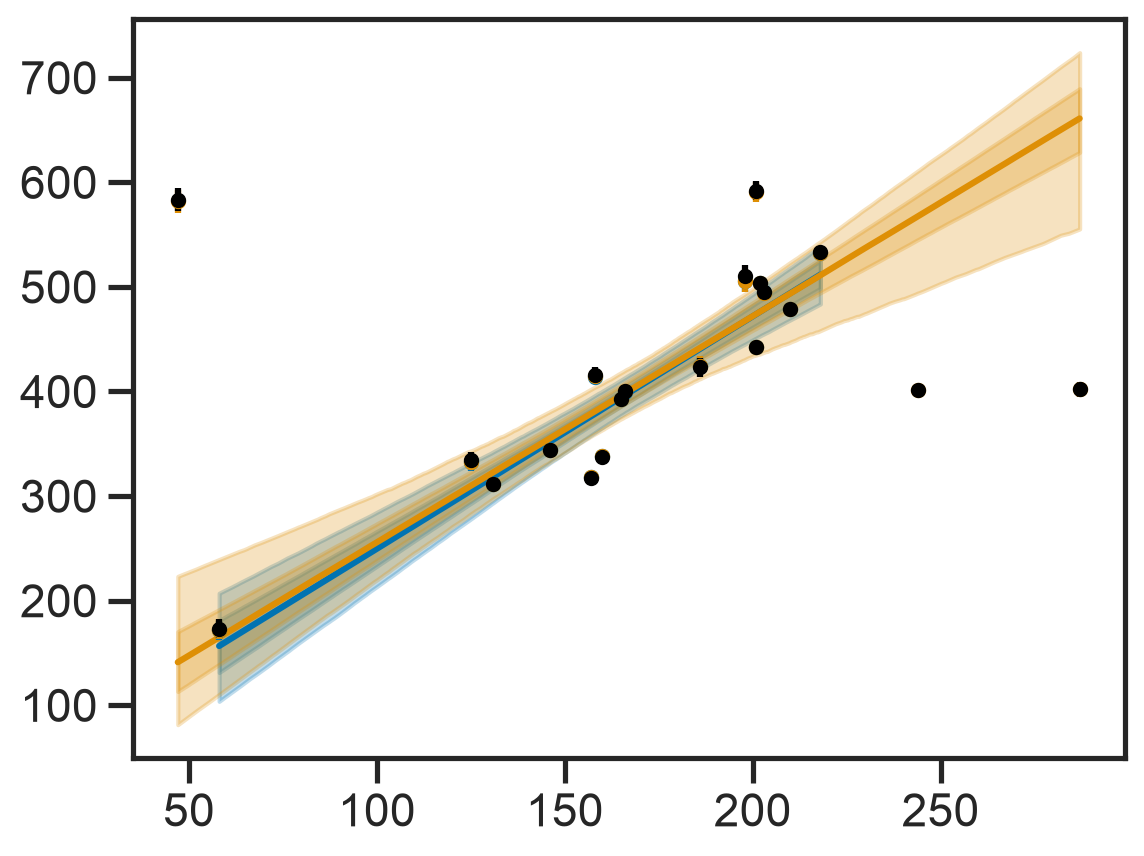

In [35]:
plot_errorbands(linspace(np.min(table1['x'][ex1N0:]), np.max(table1['x'][ex1N0:]), 1000), samples_scatter['m'], samples_scatter['b'])
plot_errorbands(linspace(np.min(table1['x']), np.max(table1['x']), 1000), samples_outliers['m'], samples_outliers['b'])
errorbar(table1['x'][ex1N0:], mean(samples_scatter['y_true'], axis=0), yerr=std(samples_scatter['y_true'], axis=0), fmt='.', color=sns.color_palette()[0])
errorbar(table1['x'], mean(samples_outliers['y_true'], axis=0), yerr=std(samples_outliers['y_true'], axis=0), fmt='.', color=sns.color_palette()[1])
errorbar(table1['x'], table1['y'], yerr=table1['sigma_y'], fmt='.', color='k')

I think we are going to stop here, but useful homework could be: introduce a $x_\mathrm{true}$ parameter, and incorporate the $x$ observational uncertainties in one or more of these models and check the fits, etc.